In [8]:
# download dataset (va fi combinat cu latul tho) nici nu cred ca avem neaparat nevoie de API key ? Oricum, trebuie sa ne scapam de asta in cod real ca e security issue (100% poti faace ceva cu cheia mea :)  )

# set up Kaggle (API)

import os

# Uses the os tool we just imported to create a temporary, hidden "environment variable"
# named KAGGLE_USERNAME. When the Kaggle downloader runs later, it is programmed to
# automatically look for a variable with this exact name to know who is requesting the data.
os.environ['KAGGLE_USERNAME'] = "andrei64bit"
os.environ['KAGGLE_KEY'] = "KGAT_ba0999942ab1651a34b12ee463df341a"

# install dependencies and download the data
!pip install -q kaggle imagededup albumentations # dependencies
!kaggle datasets download -d shubhambaid/skin-burn-dataset
!unzip -q skin-burn-dataset.zip -d dataset/

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Dataset URL: https://www.kaggle.com/datasets/shubhambaid/skin-burn-dataset
License(s): CC0-1.0
100% 16.6M/16.6M [00:02<00:00, 8.49MB/s]



In [9]:
# clean data (.txt files fara imagini etc.)

import os
import glob
import shutil

base_dir = 'dataset/'
img_dir = os.path.join(base_dir, 'images')
label_dir = os.path.join(base_dir, 'labels')

os.makedirs(img_dir, exist_ok=True)
os.makedirs(label_dir, exist_ok=True)

# 1. Check for and delete empty files first
removed_empty = 0
for txt_file in glob.glob(f"{base_dir}/*.txt"):
    if os.path.getsize(txt_file) == 0:
        os.remove(txt_file)
        img_file = txt_file.replace('.txt', '.jpg')
        if os.path.exists(img_file):
            os.remove(img_file)
        removed_empty += 1

print(f"Removed {removed_empty} empty files (and their matching images).")

# 2. Identify remaining files
images = set([os.path.splitext(os.path.basename(f))[0] for f in glob.glob(f"{base_dir}/*.jpg")])
labels = set([os.path.splitext(os.path.basename(f))[0] for f in glob.glob(f"{base_dir}/*.txt")])

# 3. Clean orphaned labels
unmatched_labels = labels - images
for label in unmatched_labels:
    os.remove(f"{base_dir}/{label}.txt")

print(f"Removed {len(unmatched_labels)} orphaned label files.")

# 4. Move matched pairs into dedicated subdirectories
matched_stems = labels.intersection(images)
for stem in matched_stems:
    shutil.move(f"{base_dir}/{stem}.jpg", os.path.join(img_dir, f"{stem}.jpg"))
    shutil.move(f"{base_dir}/{stem}.txt", os.path.join(label_dir, f"{stem}.txt"))

print(f"Successfully separated {len(matched_stems)} image/label pairs into '{img_dir}' and '{label_dir}'.")

Removed 4 empty files (and their matching images).
Removed 216 orphaned label files.
Successfully separated 1221 image/label pairs into 'dataset/images' and 'dataset/labels'.


In [10]:
# dedupe images

from imagededup.methods import PHash
import os

# Define the paths created in the previous step
image_dir = 'dataset/images/'
label_dir = 'dataset/labels/'

# Initialize Perceptual Hashing
phasher = PHash()
encodings = phasher.encode_images(image_dir=image_dir)
duplicates = phasher.find_duplicates(encoding_map=encodings)

removed_count = 0
deleted_images = set() # Tracks deleted files to handle cross-referenced duplicates

for original_file, duplicate_list in duplicates.items():
    # Only process if this "original" hasn't already been deleted as a duplicate of something else
    if original_file not in deleted_images and os.path.exists(os.path.join(image_dir, original_file)):

        for dup in duplicate_list:
            if dup not in deleted_images:
                # 1. Define paths for both the duplicate image and its matching label
                dup_img_path = os.path.join(image_dir, dup)
                dup_label_name = os.path.splitext(dup)[0] + '.txt'
                dup_label_path = os.path.join(label_dir, dup_label_name)

                # 2. Delete the duplicate image
                if os.path.exists(dup_img_path):
                    os.remove(dup_img_path)
                    deleted_images.add(dup) # Mark as deleted so it's ignored later in the loop
                    removed_count += 1

                # 3. Delete the corresponding duplicate label file
                if os.path.exists(dup_label_path):
                    os.remove(dup_label_path)

print(f"Removed {removed_count} duplicate image/label pairs.")

2026-11-13 16:14:22,643: INFO Start: Calculating hashes...
INFO:imagededup.methods.hashing:Start: Calculating hashes...
100%|██████████| 1221/1221 [00:05<00:00, 235.75it/s]
2026-11-13 16:14:27,941: INFO End: Calculating hashes!
INFO:imagededup.methods.hashing:End: Calculating hashes!
/usr/local/lib/python3.13/dist-packages/imagededup/methods/hashing.py:317: RuntimeWarning: Parameter num_enc_workers has no effect since encodings are already provided
  warnings.warn('Parameter num_enc_workers has no effect since encodings are already provided', RuntimeWarning)
2026-11-13 16:14:27,944: INFO Start: Evaluating hamming distances for getting duplicates
INFO:imagededup.methods.hashing:Start: Evaluating hamming distances for getting duplicates
2026-11-13 16:14:27,947: INFO Start: Retrieving duplicates using Cython Brute force algorithm
INFO:imagededup.handlers.search.retrieval:Start: Retrieving duplicates using Cython Brute force algorithm
100%|██████████| 1221/1221 [00:00<00:00, 2508.68it/s]
2

Removed 176 duplicate image/label pairs.


In [11]:
#split train-test (desi pretty sure ca nu mai e de folos functia ca am mai mixat training / validat date cu alta baza de date ; poti antrena modelel timpurii tho sa vezi ce si cum)

import os
from sklearn.model_selection import train_test_split

# Point to the new dedicated images directory
image_dir = 'dataset/images/'

# 1. Gather all image filenames from the correct folder
image_files = [f for f in os.listdir(image_dir) if f.endswith('.jpg')]

# 2. Safety check to ensure the list is not empty
if len(image_files) == 0:
    raise ValueError(f"No images found in '{image_dir}'. Check your folder paths.")

# 3. Perform the split
train_images, val_images = train_test_split(image_files, test_size=0.2, random_state=42)

print(f"Total valid images: {len(image_files)}")
print(f"Training images: {len(train_images)}")
print(f"Validation images: {len(val_images)}")

Total valid images: 1045
Training images: 836
Validation images: 209


In [12]:
#print images cu tot cu YOLO format (am stricat-o tho ca m-am enervat cand nu mergea modelul :)   )

import os
import glob
import cv2
import matplotlib.pyplot as plt
import random

# visualize original images with YOLO bounding boxes
def view_original_with_boxes(num_images=6, folder_path="dataset"):
    print(f"\n--- Loading images from {folder_path} with YOLO bounding boxes ---")

    txt_files = glob.glob(f"{folder_path}/*.txt")

    # randomly select a handful of files so we don't crash the browser
    files_to_show = random.sample(txt_files, min(num_images, len(txt_files)))

    plt.figure(figsize=(18, 10))
    classes = ['1st Degree', '2nd Degree', '3rd Degree']

    for i, txt_path in enumerate(files_to_show):
        img_path = txt_path.replace('.txt', '.jpg') # find the matching image

        # open the image and fix the color format
        img = cv2.imread(img_path)
        if img is None: continue # safety check in case the image was deleted
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape

        # open the YOLO text file to get the math
        with open(txt_path, 'r') as f:
            data = f.readline().split()
            if not data:
                continue

            # extract the 5 YOLO variables
            class_id = int(float(data[0])) #fix because of forcing the string "2.0" directly into an int()causes a crash because it doesn't expect a decimal point.
            cx, cy, bw, bh = map(float, data[1:])

            # convert the YOLO percentages into exact pixel coordinates
            x1 = int((cx - bw / 2) * w) # left edge
            y1 = int((cy - bh / 2) * h) # top edge
            x2 = int((cx + bw / 2) * w) # right edge
            y2 = int((cy + bh / 2) * h) # bottom edge

            # draw a bright Red box around the burn (thickness: 3 pixels)
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 3)

            # create a text label showing the Severity and the h/w percentages
            label_text = f"{classes[class_id]} (w:{bw:.2f}, h:{bh:.2f})"

        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(f"{os.path.basename(img_path)}\n{label_text}", fontsize=12)
        plt.axis('off')

    plt.tight_layout()
    plt.show()


view_original_with_boxes(num_images=6)

# print the final counts of the train and test sets
print("\n--- Final Dataset Counts ---")


train_count = len(glob.glob("clean_data/train/*/*.jpg"))


test_count = len(glob.glob("clean_data/test/*/*.jpg"))

print(f"Total Training Images: {train_count}")
print(f"Total Testing Images: {test_count}")
print(f"Total Overall: {train_count + test_count}")


--- Loading images from dataset with YOLO bounding boxes ---


<Figure size 1800x1000 with 0 Axes>


--- Final Dataset Counts ---
Total Training Images: 0
Total Testing Images: 0
Total Overall: 0


In [13]:
# resize data to 224x224 si fortare RGB (3 channels) -> desi nu mai e nevoie ca modelul deja face asta
# , dar oricum am zis ca la mod general ar fi bine sa avem ceva de resizing (cine stie ce model vom folosi ; again, asta era inainte sa fol modelul asta care deja face resize)

import os
import glob
import cv2
import albumentations as A

# create a brand new output folder so re-running is 100% safe
output_dir = "dataset_224"
os.makedirs(output_dir, exist_ok=True)

# define the pipeline: Augment clarity (CLAHE) and resize to exactly 224x224
# BboxParams tells Albumentations to automatically recalculate the YOLO boxes to match the new 224x224 size
transform = A.Compose([
    A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=1.0),
    A.Resize(224, 224)
], bbox_params=A.BboxParams(format='yolo', min_visibility=0.1))

image_files = glob.glob("dataset/*.jpg")
processed_count = 0

print("Augmenting, forcing 3 channels, and resizing images to 224x224...")

for img_path in image_files:
    txt_path = img_path.replace('.jpg', '.txt')

    # read the image and FORCE it to be exactly 3 channels (BGR because of cv2!)
    img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if img is None: continue # safety check in case a file is missing or corrupted

    # convert OpenCV's default BGR format to standard RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    bboxes = []

    # read the YOLO labels and convert them to the Albumentations format: [cx, cy, w, h, class_id]
    if os.path.exists(txt_path):
        with open(txt_path, 'r') as f:
            for line in f.readlines():
                parts = line.split()
                if len(parts) >= 5:
                    class_id = int(parts[0])
                    cx, cy, bw, bh = map(float, parts[1:5])
                    bboxes.append([cx, cy, bw, bh, class_id])

    # apply the transformations (this resizes the image AND recalculates the math for the boxes)
    augmented = transform(image=img, bboxes=bboxes)
    aug_img = augmented['image']
    aug_bboxes = augmented['bboxes']

    base_name = os.path.basename(img_path)

    # convert back to BGR so OpenCV can save the image correctly to your hard drive
    new_img_path = f"{output_dir}/{base_name}"
    aug_img_bgr = cv2.cvtColor(aug_img, cv2.COLOR_RGB2BGR)
    cv2.imwrite(new_img_path, aug_img_bgr)

    # save the updated .txt file containing the new math into the new folder
    new_txt_path = f"{output_dir}/{base_name.replace('.jpg', '.txt')}"
    with open(new_txt_path, 'w') as f:
        for bbox in aug_bboxes:
            cx, cy, bw, bh, class_id = bbox
            # YOLO format requires the class_id to be first: class_id cx cy w h
            f.write(f"{class_id} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}\n")

    processed_count += 1

print(f"Successfully processed and saved {processed_count} files to '{output_dir}/'")

Augmenting, forcing 3 channels, and resizing images to 224x224...
Successfully processed and saved 0 files to 'dataset_224/'


In [14]:
view_original_with_boxes(num_images=6, folder_path="dataset_224")
# view a few images (6 sa nu crape Colab-ul) ; again, am strcat somehow


--- Loading images from dataset_224 with YOLO bounding boxes ---


<Figure size 1800x1000 with 0 Axes>

In [ ]:
# NU MAI RULA ASTA DECAT PT MODELUL VIZIONAT MODEL TIMPURIU ; era basically a 2-a incercare, cu toate augmentarile de imagine and whatnot, dar nu invata nimic din date
# (daca vezi ca instant merge acuratetea la 100% si loss-ul e incredibil de mic, e clar ; cred ca are early stopping, deci se opreste mai repede decat am dat
# eu nr epoci ; ulterior mai sunt puse metode de image augmentation, learning rate-ul e si el variabil (scade cu timpul) ; de aici inclusiv se merge pe ideea ca mai intai
# antrenezi ce nu e modelul (i dai freeze)0 si apoi antrenezi modelul (unfreeze) -> kinda ce facea Popa la PI cu freeze layers ; te mai poti juca cu parametri
# daca e, ca aia inseamna fine tuning, inclusiv adding layers, dar mna ; modelul final teoretic pare capabil sa faca ce vrem ; vezi ca tot ce e aici trb refacut daca
# se deconecteaza GPU si trb reluat deci de sus :) incearca sa nu stai mai mult de 1-2 ore si sa mai iesi ca mi se pare sincer ca-ti da lock out mai
# repede daca stai f mult intr-o sesiune

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input
from tensorflow.keras import layers, models

# ==========================================
# 1. LOAD DATA & USE MOBILENET PREPROCESSING
# ==========================================
data_dir = 'dataset/'
BATCH_SIZE = 16
IMG_SIZE = (224, 224)
SEED = 123

# Create TRAINING dataset
train_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

# Extract class names and count HERE, before the dataset is transformed
class_names = train_dataset.class_names
num_classes = len(class_names)
print(f"Found {num_classes} classes: {class_names}")

# Create VALIDATION dataset
val_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

# Apply MobileNetV3 preprocessing
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
val_dataset = val_dataset.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)

# Cache and prefetch for performance
train_dataset = train_dataset.cache().prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)


# ==========================================
# 2. BUILD MODEL (PHASE 1: FROZEN BACKBONE)
# ==========================================
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomContrast(0.10)
], name="data_augmentation")

base_model = MobileNetV3Small(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze base model completely for Phase 1
base_model.trainable = False

model = models.Sequential([
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='softmax') # Dynamically matches your dataset
])

# Train classification head first with standard learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("--- PHASE 1: Training Classification Head (50 Epochs) ---")
model.fit(train_dataset, validation_data=val_dataset, epochs=50)


# ==========================================
# 3. PHASE 2: FINE-TUNE BACKBONE (FREEZE BN LAYERS)
# ==========================================
base_model.trainable = True

# CRITICAL: Freeze Batch Normalization layers to prevent statistics drift
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with very low learning rate for fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,          # Stop if validation loss doesn't improve for 5 epochs
    restore_best_weights=True
)

# Add it to your fit function:
model.fit(train_dataset, validation_data=val_dataset, epochs=150, callbacks=[early_stopping])

Found 1045 files belonging to 2 classes.
Using 836 files for training.
Found 2 classes: ['images', 'labels']
Found 1045 files belonging to 2 classes.
Using 209 files for validation.
4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
--- PHASE 1: Training Classification Head (50 Epochs) ---
Epoch 1/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - accuracy: 0.9653 - loss: 0.0932 - val_accuracy: 1.0000 - val_loss: 0.0080
Epoch 2/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 1.0000 - loss: 0.0071 - val_accuracy: 1.0000 - val_loss: 0.0046
Epoch 3/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 1.0000 - loss: 0.0037 - val_accuracy: 1.0000 - val_loss: 0.0033
Epoch 4/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 1.0000 - loss: 0.0024 - val_accuracy: 1.0000 - val_loss: 0.0025
Epoch 5/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 1.0000 - loss: 0.0024 - val_accuracy: 1.0000 - val_loss: 0.0019
Epoch 6/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 1.0000 - lo

KeyboardInterrupt: 

In [ ]:
# Save the fully trained model to a file
model.save('suspicious_burn_model.keras') # salvare LOCALA (se pierde dupa deconectare GPU ; trb mount pe drive / download local cum am fct jos de tot)
print("Model saved successfully!")

Model saved successfully!


In [ ]:
!pip install -q kagglehub # acelasi model, incerc cross-validation (testare "reala") cu un alt set de date gigantic ; asta e folosit ulterior cu cel de sus
# pt training & validation, urmand sa existe o alta baza de date pt cross-validation ; sper ca am dat shuffle btw la training data and whatnot... ; avea parca
# ceva probleme varianta asta ca nush ce facusem cu Gemini, dar o poti repara daca chiar ; e useless for now bucatta asta ; nu mai rulezi inca anyway de aici
import kagglehub
import os
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input

print("1. Downloading a completely different dataset (by Fares Abbas)...")
dataset_path = kagglehub.dataset_download("faresabbasai2022/skin-burn-dataset")
print(f"Downloaded to: {dataset_path}")

# Automatically find the directory that contains the class subfolders
test_dir = None
for root, dirs, files in os.walk(dataset_path):
    if any(f.lower().endswith(('.png', '.jpg', '.jpeg')) for f in files):
        test_dir = os.path.dirname(root)
        break

if test_dir is None:
    raise ValueError("Could not find image folders in the downloaded dataset.")

print("\n2. Loading your trained model...")
loaded_model = tf.keras.models.load_model('suspicious_burn_model.keras')

# Restrict to the two known classes that match your trained model
my_two_classes = ['1st degree burn', '2nd degree burn']
print(f"Restricting test data to only known classes: {my_two_classes}")

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

print("\n3. Loading new dataset for evaluation...")
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    class_names=my_two_classes,  # Correct parameter for Keras
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

# Apply the same MobileNet preprocessing you used during training
test_dataset = test_dataset.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

print("\n--- FINAL VERDICT: Evaluating Model on Unseen Data ---")
loss, accuracy = loaded_model.evaluate(test_dataset)

print(f"\nReal-World Accuracy on Unseen Data: {accuracy * 100:.2f}%")
print(f"Real-World Loss on Unseen Data: {loss:.4f}")

1. Downloading a completely different dataset (by Fares Abbas)...


100%|██████████| 109M/109M [00:01<00:00, 92.6MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/faresabbasai2022/skin-burn-dataset/versions/1

2. Loading your trained model...


ValueError: File not found: filepath=suspicious_burn_model.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
import os # tot varianta veche si nu e de rulat ; aici am scapat de not learning anything si am revenit la "attempt 1" cu multe augmentari, dar e prea mic modelul sa
import glob # fie useful ; nu rula daca vrei modelul bun
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

# ==========================================
# 1. PARSE SHUBHAMBAID DATASET (.txt Annotations)
# ==========================================
img_dir = 'dataset/images/'
label_dir = 'dataset/labels/'

x_paths = []
y_labels = []

print("Parsing Shubhambaid dataset images and YOLO label files...")
for img_file in os.listdir(img_dir):
    if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
        img_path = os.path.join(img_dir, img_file)
        label_file = os.path.splitext(img_file)[0] + '.txt'
        label_path = os.path.join(label_dir, label_file)

        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                lines = f.readlines()
                if lines:
                    # Extract class_id (0, 1, or 2 for burn degree)
                    class_id = int(float(lines[0].split()[0]))
                    if class_id in [0, 1, 2]:
                        x_paths.append(img_path)
                        y_labels.append(class_id)

y_labels_cat = tf.keras.utils.to_categorical(y_labels, num_classes=3)

# ==========================================
# 2. TRAIN / VALIDATION SPLIT (80% / 20%)
# ==========================================
train_paths, val_paths, train_y, val_y = train_test_split(
    x_paths, y_labels_cat, test_size=0.2, random_state=123, stratify=y_labels
)

print(f"Dataset Split: {len(train_paths)} training samples | {len(val_paths)} validation samples.")

# ==========================================
# 3. DATASET PIPELINES
# ==========================================
def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (224, 224))
    img = preprocess_input(img)
    return img, label

BATCH_SIZE = 16

train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_y))
train_ds = train_ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_y))
val_ds = val_ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# ==========================================
# 4. MODEL BUILD & TWO-PHASE TRAINING
# ==========================================
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(0.2, 0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
    layers.GaussianNoise(0.1)
], name="data_augmentation")

base_model = MobileNetV3Small(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False

model = models.Sequential([
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.5),
    layers.Dense(3, activation='softmax')
])

# Phase 1: Train Classification Head
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_phase1 = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

print("\n--- PHASE 1: Training Classification Head ---")
model.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=[early_stop_phase1])

# Phase 2: Fine-Tune Backbone
base_model.trainable = True
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-6),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_phase2 = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

print("\n--- PHASE 2: Fine-Tuning Backbone ---")
model.fit(train_ds, validation_data=val_ds, epochs=100, callbacks=[early_stop_phase2])

print("\nTraining complete! Saving model...")
model.save('best_burn_model_shubhambaid.keras')

Parsing Shubhambaid dataset images and YOLO label files...
Dataset Split: 836 training samples | 209 validation samples.

--- PHASE 1: Training Classification Head ---
Epoch 1/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 58ms/step - accuracy: 0.3911 - loss: 1.3171 - val_accuracy: 0.4976 - val_loss: 0.9545
Epoch 2/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.4545 - loss: 1.0849 - val_accuracy: 0.5742 - val_loss: 0.8679
Epoch 3/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.5108 - loss: 1.0235 - val_accuracy: 0.6124 - val_loss: 0.8137
Epoch 4/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.5287 - loss: 1.0032 - val_accuracy: 0.6364 - val_loss: 0.7984
Epoch 5/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.5598 - loss: 0.8987 - val_accuracy: 0.6603 - val_loss: 0.7525
Epoch 6/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.5909 - loss: 0.9116 - val_accuracy: 0.6699 - val_loss: 0.7625
Epoch 7/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.5706

In [ ]:
import kagglehub # mda, aici vezi cross-validation pt modelul oribil ; ignora
import os
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input

# ==========================================
# 1. DOWNLOAD UNSEEN TEST DATASET
# ==========================================
print("Downloading unseen benchmark dataset (faresabbasai2022/skin-burn-dataset)...")
dataset_path = kagglehub.dataset_download("faresabbasai2022/skin-burn-dataset")

test_dir = None
for root, dirs, files in os.walk(dataset_path):
    if any(f.lower().endswith(('.png', '.jpg', '.jpeg')) for f in files):
        test_dir = os.path.dirname(root)
        break

if test_dir is None:
    raise ValueError("Could not find image folders in downloaded dataset.")

# ==========================================
# 2. LOAD TRAINED MODEL
# ==========================================
print("\nLoading model trained on Shubhambaid dataset...")
loaded_model = tf.keras.models.load_model('best_burn_model_shubhambaid.keras')

# ==========================================
# 3. EVALUATE ON UNSEEN DATA
# ==========================================
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

test_dataset = test_dataset.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

print("\n--- FINAL VERDICT: Real-World Evaluation on Unseen Dataset ---")
loss, accuracy = loaded_model.evaluate(test_dataset)

print(f"\nReal-World Accuracy on Unseen Dataset: {accuracy * 100:.2f}%")
print(f"Real-World Loss on Unseen Dataset: {loss:.4f}") # 54 accuracy...nope ; trained on big dataset, cross-validated on smaller one

Using Colab cache for faster access to the 'skin-burn-dataset' dataset.

Loading model trained on Shubhambaid dataset...
Found 399 files belonging to 3 classes.

--- FINAL VERDICT: Real-World Evaluation on Unseen Dataset ---
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.5414 - loss: 1.0997

Real-World Accuracy on Unseen Dataset: 54.14%
Real-World Loss on Unseen Dataset: 1.0997


In [ ]:
import os # pretty sure ca celula asta e in plus si era un cod half baked a variantei de mai jos ; don't run anyway
import glob
import kagglehub
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import MobileNetV3Large
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, Callback

# Create a dedicated directory to store the 5-epoch backups
os.makedirs('checkpoints', exist_ok=True)

x_paths = []
y_labels = []

# ==========================================
# 1. PARSE DATASET A: SHUBHAMBAID (.txt annotations)
# ==========================================
img_dir_a = 'dataset/images/'
label_dir_a = 'dataset/labels/'

print("Loading Dataset A (Shubhambaid)...")
if os.path.exists(img_dir_a):
    for img_file in os.listdir(img_dir_a):
        if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
            img_path = os.path.join(img_dir_a, img_file)
            label_file = os.path.splitext(img_file)[0] + '.txt'
            label_path = os.path.join(label_dir_a, label_file)

            if os.path.exists(label_path):
                with open(label_path, 'r') as f:
                    lines = f.readlines()
                    if lines:
                        class_id = int(float(lines[0].split()[0]))
                        if class_id in [0, 1, 2]:
                            x_paths.append(img_path)
                            y_labels.append(class_id)

print(f" -> Found {len(x_paths)} samples in Dataset A.")

# ==========================================
# 2. PARSE DATASET B: FARES ABBAS (Folder structure)
# ==========================================
print("\nLoading Dataset B (Fares Abbas)...")
ds_b_path = kagglehub.dataset_download("faresabbasai2022/skin-burn-dataset")

class_mapping_b = {
    '1st degree burn': 0, '2nd degree burn': 1,
    '3nd degree burn': 2, '3rd degree burn': 2
}

ds_b_count = 0
for root, dirs, files in os.walk(ds_b_path):
    folder_name = os.path.basename(root).lower().strip()

    matched_class = None
    for key, cid in class_mapping_b.items():
        if key in folder_name:
            matched_class = cid
            break

    if matched_class is not None:
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                x_paths.append(os.path.join(root, file))
                y_labels.append(matched_class)
                ds_b_count += 1

print(f" -> Found {ds_b_count} samples in Dataset B.")
print(f"Total Combined Training Pool: {len(x_paths)} images.")

# ==========================================
# 3. STRATIFIED TRAIN / VALIDATION SPLIT (80% / 20%)
# ==========================================
y_labels_cat = tf.keras.utils.to_categorical(y_labels, num_classes=3)
train_paths, val_paths, train_y, val_y = train_test_split(
    x_paths, y_labels_cat, test_size=0.2, random_state=123, stratify=y_labels
)
print(f"\nSplit: {len(train_paths)} Train | {len(val_paths)} Internal Validation.")

# ==========================================
# 4. TF.DATA PIPELINES
# ==========================================
def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (224, 224))
    img = preprocess_input(img)
    return img, label

BATCH_SIZE = 16

train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_y))
train_ds = train_ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_y))
val_ds = val_ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# ==========================================
# 5. AUTO-RESUME LOGIC & CUSTOM CALLBACK
# ==========================================
def get_latest_checkpoint(phase_prefix):
    """Scans the checkpoints folder and returns the path & epoch number of the latest save."""
    files = glob.glob(f"checkpoints/{phase_prefix}_epoch_*.keras")
    if not files:
        return None, 0
    # Sort files sequentially based on their epoch integer
    files.sort(key=lambda x: int(x.split('_epoch_')[-1].split('.keras')[0]))
    latest_file = files[-1]
    latest_epoch = int(latest_file.split('_epoch_')[-1].split('.keras')[0])
    return latest_file, latest_epoch

class CheckpointEveryNEpochs(Callback):
    """Custom callback to save intermediate models without overwriting."""
    def __init__(self, phase_prefix, save_freq=5):
        super().__init__()
        self.phase_prefix = phase_prefix
        self.save_freq = save_freq

    def on_epoch_end(self, epoch, logs=None):
        current_epoch = epoch + 1
        if current_epoch % self.save_freq == 0:
            filepath = f"checkpoints/{self.phase_prefix}_epoch_{current_epoch:02d}.keras"
            self.model.save(filepath)
            print(f"\n[Auto-Saved Intermediate Checkpoint: {filepath}]")

# ==========================================
# 6. PHASE 1: TRAIN CLASSIFICATION HEAD
# ==========================================
phase1_latest, p1_epoch = get_latest_checkpoint("phase1")

if os.path.exists('checkpoints/phase1_complete.keras'):
    print("\n--- Phase 1 already complete. Loading saved model... ---")
    model = tf.keras.models.load_model('checkpoints/phase1_complete.keras')
    p1_epoch = 50 # Signal to skip Phase 1 training loop
elif phase1_latest:
    print(f"\n--- Resuming Phase 1 from epoch {p1_epoch}... ---")
    model = tf.keras.models.load_model(phase1_latest)
else:
    print("\n--- Starting Phase 1 from scratch... ---")
    data_augmentation = tf.keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.25),
        layers.RandomZoom(0.2, 0.2),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.2),
        layers.GaussianNoise(0.1)
    ], name="data_augmentation")

    base_model = MobileNetV3Large(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
    base_model.trainable = False

    model = models.Sequential([
        data_augmentation,
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.5),
        layers.Dense(3, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    p1_epoch = 0

# Execute Phase 1 Training if not already finished
if p1_epoch < 50:
    lr_scheduler_p1 = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5, verbose=1)
    early_stop_p1 = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

    model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=50,
        initial_epoch=p1_epoch, # Automatically fast-forwards to where you left off
        callbacks=[early_stop_p1, lr_scheduler_p1, CheckpointEveryNEpochs("phase1", save_freq=5)]
    )
    # Save a bridge file to prove Phase 1 finished successfully
    model.save('checkpoints/phase1_complete.keras')
    print("Phase 1 Complete and Saved.")


# ==========================================
# 7. PHASE 2: FINE-TUNE BACKBONE
# ==========================================
phase2_latest, p2_epoch = get_latest_checkpoint("phase2")

if os.path.exists('combined_burn_model_large.keras'):
    print("\n--- Phase 2 already complete. Model is fully trained! ---")
else:
    if phase2_latest:
        print(f"\n--- Resuming Phase 2 Fine-Tuning from epoch {p2_epoch}... ---")
        # Loading a Phase 2 checkpoint inherently loads the un-frozen architecture
        model = tf.keras.models.load_model(phase2_latest)
    else:
        print("\n--- Starting Phase 2 Fine-Tuning... ---")
        # Dynamically retrieve the backbone from the Sequential structure to unfreeze it
        backbone = model.layers[1]
        backbone.trainable = True

        # Keep BatchNormalization frozen to prevent statistical collapse
        for layer in backbone.layers:
            if isinstance(layer, tf.keras.layers.BatchNormalization):
                layer.trainable = False

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
            loss='categorical_crossentropy',
            metrics=['accuracy']
        )
        p2_epoch = 0

    # Execute Phase 2 Training
    if p2_epoch < 100:
        lr_scheduler_p2 = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1)
        early_stop_p2 = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

        model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=100,
            initial_epoch=p2_epoch, # Automatically fast-forwards Phase 2
            callbacks=[early_stop_p2, lr_scheduler_p2, CheckpointEveryNEpochs("phase2", save_freq=5)]
        )
        # Save the final master artifact
        model.save('combined_burn_model_large.keras')
        print("\nTraining Complete! Final model saved to 'combined_burn_model_large.keras'.")

Loading Dataset A (Shubhambaid)...
 -> Found 1045 samples in Dataset A.

Loading Dataset B (Fares Abbas)...
Using Colab cache for faster access to the 'skin-burn-dataset' dataset.
 -> Found 5899 samples in Dataset B.
Total Combined Training Pool: 6944 images.

Split: 5555 Train | 1389 Internal Validation.

--- Starting Phase 1 from scratch... ---
12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/50
348/348 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.5126 - loss: 1.1549

KeyboardInterrupt: 

In [15]:
import os # RUN THIS DUPA CHESTIILE DE MAI SUS DE DINAINTE UNDE AM ZIS DON'T RUN ! (desi again, de unele de sus n-ai nevoie...) Anyway, asta e acum un model mai maricel
import glob # ai salvare intermediara LOCALA (daca crapa GPU, nu se salveaza!) -> trb sa fac sincer sa se salveze pe drive, dar trb dsa-i dai comanda de mount si
import kagglehub # permisiuni si e annoying... ; ai salvare la 5 epoci (gen 2-3 min) si salvare PE LAPTOP la final (poti da unui AI sa ti-l puna pe drive daca nu)
import numpy as np # TO DO LIST : leaga-l de JEV SOMEHOW :) maybe asigura-te ca e mereu restaurat inainte de training-ul asta o varianta noua in caz ca se intrerupe training-ul in mijlocc (ia gen 25-30 mins full training)
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import MobileNetV3Large
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, Callback

# Ensure checkpoint storage directory exists
CHECKPOINT_DIR = 'checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

x_paths = []
y_labels = []

# ==========================================
# 1. PARSE DATASET A: SHUBHAMBAID (.txt annotations)
# ==========================================
img_dir_a = 'dataset/images/'
label_dir_a = 'dataset/labels/'

print("Loading Dataset A (Shubhambaid)...")
if os.path.exists(img_dir_a):
    for img_file in os.listdir(img_dir_a):
        if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
            img_path = os.path.join(img_dir_a, img_file)
            label_file = os.path.splitext(img_file)[0] + '.txt'
            label_path = os.path.join(label_dir_a, label_file)

            if os.path.exists(label_path):
                with open(label_path, 'r') as f:
                    lines = f.readlines()
                    if lines:
                        class_id = int(float(lines[0].split()[0]))
                        if class_id in [0, 1, 2]:
                            x_paths.append(img_path)
                            y_labels.append(class_id)

print(f" -> Found {len(x_paths)} samples in Dataset A.")

# ==========================================
# 2. PARSE DATASET B: FARES ABBAS (Folder structure)
# ==========================================
print("\nLoading Dataset B (Fares Abbas)...")
ds_b_path = kagglehub.dataset_download("faresabbasai2022/skin-burn-dataset")

class_mapping_b = {
    '1st degree burn': 0, '2nd degree burn': 1,
    '3nd degree burn': 2, '3rd degree burn': 2
}

ds_b_count = 0
for root, dirs, files in os.walk(ds_b_path):
    folder_name = os.path.basename(root).lower().strip()

    matched_class = None
    for key, cid in class_mapping_b.items():
        if key in folder_name:
            matched_class = cid
            break

    if matched_class is not None:
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                x_paths.append(os.path.join(root, file))
                y_labels.append(matched_class)
                ds_b_count += 1

print(f" -> Found {ds_b_count} samples in Dataset B.")
print(f"Total Combined Training Pool: {len(x_paths)} images.")

# ==========================================
# 3. STRATIFIED TRAIN / VALIDATION SPLIT (80% / 20%)
# ==========================================
y_labels_cat = tf.keras.utils.to_categorical(y_labels, num_classes=3)
train_paths, val_paths, train_y, val_y = train_test_split(
    x_paths, y_labels_cat, test_size=0.2, random_state=123, stratify=y_labels
)
print(f"\nSplit: {len(train_paths)} Train | {len(val_paths)} Internal Validation.")

# ==========================================
# 4. TF.DATA PIPELINES
# ==========================================
def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (224, 224))
    img = preprocess_input(img)
    return img, label

BATCH_SIZE = 16

train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_y))
train_ds = train_ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_y))
val_ds = val_ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# ==========================================
# 5. AUTOMATIC CHECKPOINT SCANNER & 5-EPOCH SAVE CALLBACK
# ==========================================
def find_highest_checkpoint(phase_prefix):
    """Scans for saved checkpoints and returns the highest epoch file found."""
    ckpt_pattern = os.path.join(CHECKPOINT_DIR, f"{phase_prefix}_epoch_*.keras")
    ckpt_files = glob.glob(ckpt_pattern)

    if ckpt_files:
        # Extract epoch numbers as integers and find the highest one
        ckpt_files.sort(key=lambda f: int(f.rsplit('_epoch_', 1)[-1].replace('.keras', '')))
        latest_file = ckpt_files[-1]
        latest_epoch = int(latest_file.rsplit('_epoch_', 1)[-1].replace('.keras', ''))
        return latest_file, latest_epoch

    # Check for standalone saved model files as fallback
    fallback_models = [
        'combined_burn_model_large.keras',
        'combined_burn_model.keras',
        'best_burn_model_shubhambaid.keras',
        'best_burn_model_augmented.keras'
    ]
    for model_file in fallback_models:
        if os.path.exists(model_file) and phase_prefix == 'phase2':
            return model_file, 0

    return None, 0

class CheckpointEveryNEpochs(Callback):
    """Saves model weights every N epochs."""
    def __init__(self, phase_prefix, save_freq=5):
        super().__init__()
        self.phase_prefix = phase_prefix
        self.save_freq = save_freq

    def on_epoch_end(self, epoch, logs=None):
        current_epoch = epoch + 1
        if current_epoch % self.save_freq == 0:
            filepath = os.path.join(CHECKPOINT_DIR, f"{self.phase_prefix}_epoch_{current_epoch:02d}.keras")
            self.model.save(filepath)
            print(f"\n [Saved Checkpoint: {filepath}]")

# ==========================================
# 6. PHASE 1: TRAIN CLASSIFICATION HEAD
# ==========================================
p1_checkpoint, p1_epoch = find_highest_checkpoint("phase1")
phase1_complete_path = os.path.join(CHECKPOINT_DIR, 'phase1_complete.keras')

if os.path.exists(phase1_complete_path):
    print("\n--- Phase 1 complete. Loading saved Phase 1 model... ---")
    model = tf.keras.models.load_model(phase1_complete_path)
    p1_epoch = 50
elif p1_checkpoint and p1_epoch > 0:
    print(f"\n--- Resuming Phase 1 from highest checkpoint: '{p1_checkpoint}' (Epoch {p1_epoch}) ---")
    model = tf.keras.models.load_model(p1_checkpoint)
else:
    print("\n--- Building new MobileNetV3Large model for Phase 1 ---")
    data_augmentation = tf.keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.25),
        layers.RandomZoom(0.2, 0.2),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.2),
        layers.GaussianNoise(0.1)
    ], name="data_augmentation")

    base_model = MobileNetV3Large(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
    base_model.trainable = False

    model = models.Sequential([
        data_augmentation,
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.5),
        layers.Dense(3, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    p1_epoch = 0

# Train Phase 1 if not finished
if p1_epoch < 50:
    lr_scheduler_p1 = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5, verbose=1)
    early_stop_p1 = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

    model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=50,
        initial_epoch=p1_epoch,
        callbacks=[early_stop_p1, lr_scheduler_p1, CheckpointEveryNEpochs("phase1", save_freq=5)]
    )
    model.save(phase1_complete_path)
    print("--- Phase 1 Complete and Saved. ---")

# ==========================================
# 7. PHASE 2: FINE-TUNE BACKBONE
# ==========================================
p2_checkpoint, p2_epoch = find_highest_checkpoint("phase2")

if os.path.exists('combined_burn_model_large.keras') and p2_epoch == 0:
    print("\n--- Model is already fully trained and saved as 'combined_burn_model_large.keras'. ---")
else:
    if p2_checkpoint and p2_epoch > 0:
        print(f"\n--- Resuming Phase 2 Fine-Tuning from highest checkpoint: '{p2_checkpoint}' (Epoch {p2_epoch}) ---")
        model = tf.keras.models.load_model(p2_checkpoint)
    else:
        print("\n--- Unfreezing backbone for Phase 2 Fine-Tuning ---")
        backbone = model.layers[1]
        backbone.trainable = True

        # Freeze Batch Normalization layers to avoid statistic drift
        for layer in backbone.layers:
            if isinstance(layer, tf.keras.layers.BatchNormalization):
                layer.trainable = False

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
            loss='categorical_crossentropy',
            metrics=['accuracy']
        )
        p2_epoch = 0

    if p2_epoch < 100:
        lr_scheduler_p2 = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1)
        early_stop_p2 = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

        model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=100,
            initial_epoch=p2_epoch,
            callbacks=[early_stop_p2, lr_scheduler_p2, CheckpointEveryNEpochs("phase2", save_freq=5)]
        )
        model.save('combined_burn_model_large.keras')
        print("\n--- Training Complete! Final model saved to 'combined_burn_model_large.keras' ---")

Loading Dataset A (Shubhambaid)...
 -> Found 1045 samples in Dataset A.

Loading Dataset B (Fares Abbas)...
Using Colab cache for faster access to the 'skin-burn-dataset' dataset.
 -> Found 5899 samples in Dataset B.
Total Combined Training Pool: 6944 images.

Split: 5555 Train | 1389 Internal Validation.

--- Building new MobileNetV3Large model for Phase 1 ---
12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/50
348/348 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - accuracy: 0.5554 - loss: 1.0318 - val_accuracy: 0.6703 - val_loss: 0.6974 - learning_rate: 0.0010
Epoch 2/50
348/348 ━━━━━━━━━━━━━━━━━━━━ 20s 50ms/step - accuracy: 0.6389 - loss: 0.8191 - val_accuracy: 0.6875 - val_loss: 0.6776 - learning_rate: 0.0010
Epoch 3/50
348/348 ━━━━━━━━━━━━━━━━━━━━ 21s 56ms/step - accuracy: 0.6461 - loss: 0.7886 - val_accuracy: 0.6976 - val_loss: 0.6548 - learning_rate: 0.0010
Epoch 4/50
348/348 ━━━━━━━━━━━━━━━━━━━━ 20s 51ms/step - accuracy: 0.6574 - loss: 0.7798 - val_accuracy: 0.6818 - val_loss:

In [16]:
# Save the model object currently in GPU memory to the runtime disk
model.save('current_gpu_model.keras') # e logic ; btw, ofc ca mai sunt muuulte greseli de cod, dar cum oricum nu e dcat orientativ...mda :)
print("Model saved to session disk successfully!")

Model saved to session disk successfully!


In [17]:
from google.colab import files

# Triggers a direct browser download to your PC Downloads folder
files.download('current_gpu_model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Using Colab cache for faster access to the 'skin-burn-dataset-cleanedv2' dataset.
Loaded 1033 images from Dataset C for external validation.

Loading trained model (combined_burn_model_large.keras)...

--- FINAL VERDICT: Evaluating Model on Dataset C ---
65/65 ━━━━━━━━━━━━━━━━━━━━ 10s 117ms/step - accuracy: 0.9351 - loss: 0.1983

External Accuracy (Dataset C): 93.51%
External Loss (Dataset C): 0.1983

Generating Confusion Matrix and Metrics...

--- Detailed Classification Report ---
              precision    recall  f1-score   support

  1st Degree       0.97      0.93      0.95       400
  2nd Degree       0.90      0.94      0.92       379
  3rd Degree       0.94      0.94      0.94       254

    accuracy                           0.94      1033
   macro avg       0.94      0.94      0.94      1033
weighted avg       0.94      0.94      0.94      1033



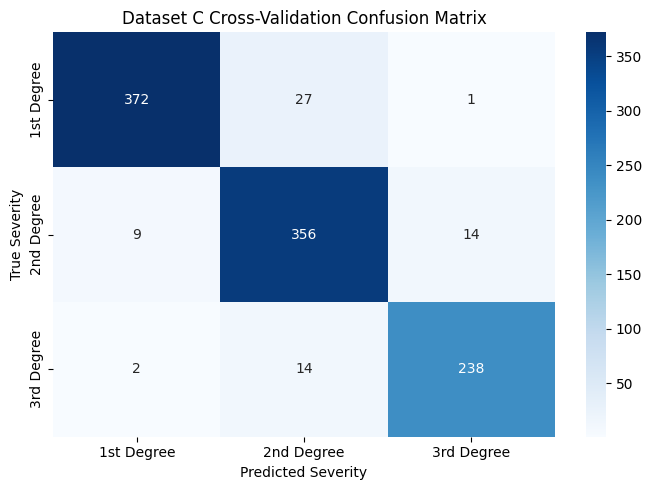

In [18]:
import os # un cross-validation fain cu o alta baza de date si informatii extra ; poti daca vrei sa iei alte baza de date / implementezi sa-ti dea mount pe drive
import kagglehub # si sa dea print la imagine cu probabilitatile claselor si poza cu imaginea s-o vezi (daca nu-s labeled imaginile pe care le iei, label them)
import numpy as np # intr-un .txt sau mna; u get the idea ; tu decizi ce si cum vrei sa faci ; mie imi pare decent, dar nici eu n-am incredere pana nu-i dau
import tensorflow as tf # niste imagini maxim de random si vad output distribution probabilities :)
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# ==========================================
# 1. DOWNLOAD REPLACEMENT DATASET C
# ==========================================
print("Downloading Dataset C (sayeemzzzaman/skin-burn-dataset-cleanedv2)...")
ds_c_path = kagglehub.dataset_download("sayeemzzzaman/skin-burn-dataset-cleanedv2")

x_test_c = []
y_test_c = []

class_mapping_c = {
    '1st': 0, 'first': 0,
    '2nd': 1, 'second': 1,
    '3rd': 2, 'third': 2, '3nd': 2
}

for root, dirs, files in os.walk(ds_c_path):
    folder_name = os.path.basename(root).lower().strip()
    matched_class = None
    for key, cid in class_mapping_c.items():
        if key in folder_name:
            matched_class = cid
            break

    if matched_class is not None:
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                x_test_c.append(os.path.join(root, file))
                y_test_c.append(matched_class)

print(f"Loaded {len(x_test_c)} images from Dataset C for external validation.")

# ==========================================
# 2. EVALUATION PIPELINE
# ==========================================
def load_and_preprocess_eval(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (224, 224))
    img = preprocess_input(img)
    return img, label

y_test_c_cat = tf.keras.utils.to_categorical(y_test_c, num_classes=3)
test_ds_c = tf.data.Dataset.from_tensor_slices((x_test_c, y_test_c_cat))
test_ds_c = test_ds_c.map(load_and_preprocess_eval, num_parallel_calls=tf.data.AUTOTUNE)
test_ds_c = test_ds_c.batch(16).prefetch(tf.data.AUTOTUNE)

# ==========================================
# 3. LOAD MODEL & EVALUATE
# ==========================================
print("\nLoading trained model (combined_burn_model_large.keras)...")
model = tf.keras.models.load_model('combined_burn_model_large.keras')

print("\n--- FINAL VERDICT: Evaluating Model on Dataset C ---")
loss, accuracy = model.evaluate(test_ds_c)
print(f"\nExternal Accuracy (Dataset C): {accuracy * 100:.2f}%")
print(f"External Loss (Dataset C): {loss:.4f}")

# ==========================================
# 4. CONFUSION MATRIX
# ==========================================
print("\nGenerating Confusion Matrix and Metrics...")
y_preds = []
y_trues = []

for images, labels in test_ds_c:
    preds = model.predict(images, verbose=0)
    y_preds.extend(np.argmax(preds, axis=1))
    y_trues.extend(np.argmax(labels.numpy(), axis=1))

class_names = ['1st Degree', '2nd Degree', '3rd Degree']

print("\n--- Detailed Classification Report ---")
print(classification_report(y_trues, y_preds, target_names=class_names))

cm = confusion_matrix(y_trues, y_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Dataset C Cross-Validation Confusion Matrix')
plt.xlabel('Predicted Severity')
plt.ylabel('True Severity')
plt.tight_layout()
plt.show()

In [19]:
import json
import requests
from google.colab import userdata

API_KEY = userdata.get("JEV_AI_API_KEY")
if not API_KEY:
    raise RuntimeError("Adaugă JEV_AI_API_KEY în Colab Secrets și activează Notebook access.")

# 1. Indicațiile hardcodate
INDICATII = {
    "go_to_hospital": "Mergi la spital / consult medical de urgență.",
    "treat_at_home": "Tratament și monitorizare la domiciliu.",
    "nothing_to_do": "Nu este necesară nicio intervenție.",
}

# 2. Înlocuiește cu output-ul real al modelului tău
probabilitati_model = {
    "clasa_usoara": 0.65,
    "clasa_moderata": 0.25,
    "clasa_severa": 0.10,
}

# 3. Cele 3 întrebări și răspunsuri din chestionar
chestionar = [
    {"intrebare": "De cât timp au apărut simptomele?", "raspuns": "2 zile"},
    {"intrebare": "Există semne de alarmă (febră mare, durere severă, dificultăți de respirație)?", "raspuns": "Nu"},
    {"intrebare": "Există afecțiuni cronice asociate?", "raspuns": "Nu"},
]

text_chestionar = "\n".join(
    f"{i+1}. {q['intrebare']} -> {q['raspuns']}" for i, q in enumerate(chestionar)
)

document = (
    f"Probabilități output model:\n{json.dumps(probabilitati_model, indent=2)}\n\n"
    f"Rezultate chestionar (3 întrebări):\n{text_chestionar}"
)

# 4. Apelul către Jev AI (cu "instructions")
response = requests.post(
    "https://jev-ai.pro/api/v1/systemone",
    headers={
        "Authorization": f"Bearer {API_KEY}",
        "Content-Type": "application/json",
    },
    json={
        "model": "jev-latest",
        "state": {"document": document},
        "questions": {
            "decizie": {
                "type": "choice",
                "instructions": "Care este recomandarea corectă combinând probabilitățile modelului și răspunsurile la chestionar?",
                "criteria": {
                    "go_to_hospital": None,
                    "treat_at_home": None,
                    "nothing_to_do": None,
                },
            }
        },
    },
    timeout=30,
)

if not response.ok:
    print("Detalii eroare server:", response.status_code, response.text)
    response.raise_for_status()

data = response.json()

decizie = data["answers"]["decizie"]["choice"]
print("Decizie Jev:", decizie)
print("Probabilități Jev:", data["answers"]["decizie"].get("probabilities"))
print("Indicație:", INDICATII[decizie])
print("Usage:", data.get("usage"))

Decizie Jev: treat_at_home
Probabilități Jev: {'go_to_hospital': 0, 'treat_at_home': 1, 'nothing_to_do': 0}
Indicație: Tratament și monitorizare la domiciliu.
Usage: {'input_tokens': 473, 'output_tokens': 51}


In [35]:
import json
import os
import requests
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input
from google.colab import userdata

# 1. Cheia Jev AI din Colab Secrets
API_KEY = userdata.get("JEV_AI_API_KEY")
if not API_KEY:
    raise RuntimeError("Adaugă JEV_AI_API_KEY în Colab Secrets (iconița de cheie din stânga) și activează Notebook access.")

# 2. Indicațiile tale hardcodate (înlocuiește cu textele finale ale aplicației tale)
INDICATII = {
    "go_to_hospital": (
        "RECOMANDARE: Prezintă-te de urgență la spital / medic.\n"
        "- Acoperă zona cu un pansament steril, curat, fără a aplica unguente sau gheață.\n"
        "- Solicită evaluare medicală imediată."
    ),
    "treat_at_home": (
        "RECOMANDARE: Îngrijire și monitorizare la domiciliu.\n"
        "- Răcește zona cu apă călduță/rece (nu gheață) timp de 10-15 minute.\n"
        "- Aplică o cremă hidratantă/calmanta potrivită și monitorizează evoluția."
    ),
    "nothing_to_do": (
        "RECOMANDARE: Nu este necesară nicio intervenție.\n"
        "- Pielea nu prezintă semne care să necesite tratament; menține zona curată."
    ),
}

# 3. Încarcă modelul antrenat (dacă nu e deja în memorie)
model_path = "combined_burn_model_large.keras"
if "model" not in globals():
    model = tf.keras.models.load_model(model_path)

# 4. Funcție de predicție pe o singură imagine (exact ca în pipeline-ul tău)
CLASS_NAMES = ["1st Degree", "2nd Degree", "3rd Degree"]

def predict_burn_probabilities(image_path: str) -> dict[str, float]:
    img_raw = tf.io.read_file(image_path)
    img = tf.image.decode_image(img_raw, channels=3, expand_animations=False)
    img = tf.image.resize(img, (224, 224))
    img = preprocess_input(img)
    img_batch = tf.expand_dims(img, axis=0)  # shape: (1, 224, 224, 3)

    probs = model.predict(img_batch, verbose=0)[0]
    return {
        CLASS_NAMES[i]: round(float(probs[i]), 4)
        for i in range(len(CLASS_NAMES))
    }

# Ia o imagine de test din dataset-ul deja descărcat (sau pune calea către o poză încărcată de tine)
sample_image_path = x_test_c[837] if "x_test_c" in globals() and len(x_test_c) > 0 else val_paths[0]
probabilitati_model = predict_burn_probabilities(sample_image_path)

# 5. Cele 3 întrebări și răspunsuri din chestionar
chestionar = [
    {"intrebare": "Cât de mare este suprafața afectată (mai mare decât palma pacientului)?", "raspuns": "Nu"},
    {"intrebare": "Este localizată pe față, mâini, picioare, articulații sau zona genitală?", "raspuns": "Nu"},
    {"intrebare": "Există vezicule (bășici) mari, piele carbonizată/albă sau durere severă?", "raspuns": "Nu"},
]

text_chestionar = "\n".join(
    f"{i+1}. {q['intrebare']} -> {q['raspuns']}" for i, q in enumerate(chestionar)
)

document = (
    f"Probabilități model clasificare arsuri (MobileNetV3Large):\n"
    f"{json.dumps(probabilitati_model, indent=2)}\n\n"
    f"Răspunsuri chestionar pacient (3 întrebări):\n"
    f"{text_chestionar}"
)

# 6. Trimite la Jev AI
response = requests.post(
    "https://jev-ai.pro/api/v1/systemone",
    headers={
        "Authorization": f"Bearer {API_KEY}",
        "Content-Type": "application/json",
    },
    json={
        "model": "jev-latest",
        "state": {"document": document},
        "questions": {
            "decizie": {
                "type": "choice",
                "instructions": (
                    "Evaluează severitatea arsurii combinând probabilitățile modelului vizual și răspunsurile din chestionar. "
                    "Alege acțiunea potrivită."
                ),
                "criteria": {
                    "go_to_hospital": (
                        "Probabilitate ridicată pentru 3rd Degree sau 2nd Degree extins, ORI dacă oricare dintre răspunsurile "
                        "din chestionar indică suprafață mare, zonă critică (față, mâini, articulații) sau vezicule severe."
                    ),
                    "treat_at_home": (
                        "Probabilitate ridicată pentru 1st Degree (sau 2nd Degree foarte limitat) fără factori de risc "
                        "în chestionar, care poate fi gestionată acasă."
                    ),
                    "nothing_to_do": (
                        "Afectare neglijabilă / fără semne de arsură activă și fără simptome sau factori de risc în chestionar."
                    ),
                },
            }
        },
    },
    timeout=30,
)

if not response.ok:
    print("Eroare server:", response.status_code, response.text)
    response.raise_for_status()

data = response.json()
decizie = data["answers"]["decizie"]["choice"]

print("Imagine testată:", sample_image_path)
print("Probabilități model local:", probabilitati_model)
print("-" * 50)
print("Decizie Jev:", decizie)
print("Distribuție Jev:", data["answers"]["decizie"].get("probabilities"))
print("\n" + INDICATII[decizie])
print("\nUsage:", data.get("usage"))

Imagine testată: /kaggle/input/skin-burn-dataset-cleanedv2/burn dataset cleaned/train/3nd degree burn/img337.jpg
Probabilități model local: {'1st Degree': 0.0, '2nd Degree': 0.0005, '3rd Degree': 0.9995}
--------------------------------------------------
Decizie Jev: go_to_hospital
Distribuție Jev: {'go_to_hospital': 0.93, 'treat_at_home': 0.03, 'nothing_to_do': 0.04}

RECOMANDARE: Prezintă-te de urgență la spital / medic.
- Acoperă zona cu un pansament steril, curat, fără a aplica unguente sau gheață.
- Solicită evaluare medicală imediată.

Usage: {'input_tokens': 683, 'output_tokens': 52}


In [26]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def plot_image_from_dir(directory_path: str, filename: str = None):
    """
    Plots an image from the given directory path.
    If `filename` is not provided, it plots the first valid image found.
    """
    valid_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tiff", ".webp"}
    dir_path = Path(directory_path)

    if not dir_path.is_dir():
        raise NotADirectoryError(f"Directory not found: {directory_path}")

    if filename:
        image_path = dir_path / filename
        if not image_path.is_file():
            raise FileNotFoundError(f"File not found: {image_path}")
    else:
        images = sorted(
            f for f in dir_path.iterdir()
            if f.is_file() and f.suffix.lower() in valid_extensions
        )
        if not images:
            raise FileNotFoundError(f"No supported images found in {directory_path}")
        image_path = images[0]

    img = mpimg.imread(image_path)
    plt.figure(figsize=(8, 6))
    plt.imshow(img)
    plt.title(image_path.name)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

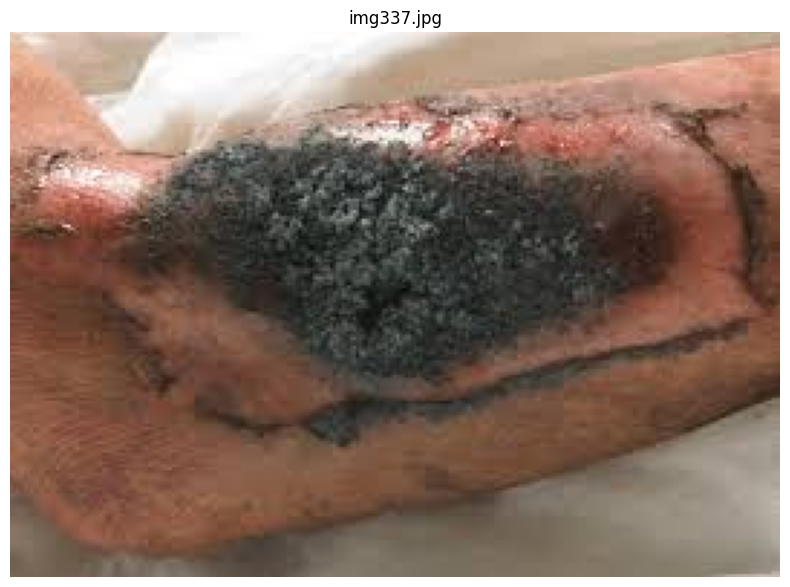

In [36]:
plot_image_from_dir("/kaggle/input/skin-burn-dataset-cleanedv2/burn dataset cleaned/train/3nd degree burn", filename = "img337.jpg")